# Sr-90 Migration from the Kurchatov Institute Radwaste Site: a 20-Input Groundwater Transport Site Model

__E. Volkova__, RRC "Kurchatov Institute", Nuclear Safety Institute, pl. Kurchatova 1, 123182 Moscow, Russia

__B. Iooss__, CEA Cadarache, DEN/DER/SESI/LCFR, Bât. 212, 13108 Saint-Paul-lez-Durance cedex, France

__F. Van Dorpe__, CEA Cadarache, DEN/DTN/SMTM/LMTE, Bât. 307, 13108 Saint-Paul-lez-Durance cedex, France

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The model, the input distributions and the 300 runs are those of Volkova, Iooss and Van Dorpe [[1]](https://doi.org/10.1007/s00477-006-0093-y), "Global sensitivity analysis for a numerical model of radionuclide migration from the RRC 'Kurchatov Institute' radwaste disposal site" (*Stochastic Environmental Research and Risk Assessment*, 2008); names and affiliations are as printed in the paper. It is a calibrated model of a real site, not a test function. The runs were made with the groundwater code MARTHE (BRGM, France). The data are the 300 input/output rows that the Virtual Library of Simulation Experiments (VLSE, S. Surjanovic and D. Bingham, Simon Fraser University) hosts as its "MARTHE" data set, taken there from the GdR MASCOT-NUM benchmark page; VLSE states that the computer code is no longer accessible. The data set is therefore **stored data**: no new runs and no gradients are possible. The notebook runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in 20 to 100 seconds, depending on machine load.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 85                          # the only seed in this notebook (bootstrap, permutations, splits)
t_start = time.perf_counter()

### Summary

Volkova, Iooss and Van Dorpe [[1]](https://doi.org/10.1007/s00477-006-0093-y) propagated 20 uncertain inputs of a MARTHE groundwater-flow and Sr-90 transport model of the Kurchatov Institute radwaste site through 300 runs, and found that the predicted 2010 concentrations at the observation wells depend mainly on the Sr-90 distribution coefficients of the first two layers (kd1, kd2) and on the infiltration rate in the leakage zones (i3). From the 300 stored runs at the 10 wells that are public, with every input mapped through its own (conditional) distribution function to independent uniform coordinates, we estimate a one-dimensional active subspace from the linear model (OLS, 500 bootstrap resamples; at the two headline wells $\lambda_1$ is 8.6 and 8.2 times the 95th percentile of its permutation null) and check it with a leave-one-out-regularized quadratic model, whose spectrum is what one direction plus noise would give. One direction carries the trend at the two wells that a linear model fits best, p104 (led by kd1 $+0.903$ and i3 $-0.365$; a cubic in $y_1$, with the direction re-estimated in every fold, has LOO $R^2 = 0.937$) and $\log_{10}$ p29K (kd2 $-0.788$, kd1 $-0.346$, i3 $+0.339$; LOO $R^2 = 0.868$); at the other eight wells that cubic explains 13–62 % of the concentration's variance, but on the rank scale nearly the same direction explains 0.505 to 0.848 of the variance at six of them, so the poor fits there are largely an effect of the concentration scale.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. Here there are no gradients, and no way to compute any, so we estimate a one-dimensional subspace from values, through the normalized coefficient vector of a linear model (OLS; for a linear $f$ it is the exact active direction), and examine the rest of the spectrum with a regularized quadratic model. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[4]](https://doi.org/10.1137/1.9781611973860).

### The model

The site, about 2 ha on the territory of the RRC "Kurchatov Institute" in Moscow, held radioactive waste in eleven temporary repositories from 1943 to 1974; Sr-90 from them reached the groundwater ([[1]](https://doi.org/10.1007/s00477-006-0093-y), Sec. 3.1). The model is a three-dimensional transient groundwater-flow and convection–dispersion transport model of Sr-90 in the upper, unconfined moraine aquifer, with sorption and radioactive decay, built in MARTHE: three layers, a uniform 5 m × 5 m planar mesh oriented south-west along the flow, on a 250 m × 350 m domain, starting from the plume observed in 2002 and predicting to the end of 2010 (Secs. 3.2–3.3). Its parameters were calibrated against observations, field and laboratory experiments and geostatistical analysis. Four zones of low conductivity in the second layer and zones of high infiltration (pipe leaks) are part of the model (Fig. 4).

The paper prints no equations. In generic form (not necessarily MARTHE's exact implementation), the head $h$ and the Darcy flux $\mathbf q$ satisfy
$$
S\,\frac{\partial h}{\partial t} = \nabla\cdot\big(K\nabla h\big) + I, \qquad \mathbf q = -K\nabla h,
$$
with hydraulic conductivity $K$ (per1–per3 by layer, perz1–perz4 in the four zones) and infiltration $I$ (i1–i3, three types of zone), and the concentration $c$ satisfies
$$
R\,\frac{\partial (\omega c)}{\partial t} = \nabla\cdot\big(\omega\,\mathbf D\,\nabla c\big) - \nabla\cdot(\mathbf q\,c) - \lambda R\,\omega c,
$$
with porosity $\omega$ (poros), a dispersion tensor $\mathbf D$ built from the longitudinal and transversal dispersivities ($\alpha_L$ = d1–d3 and $\alpha_T$ = dt1–dt3 by layer) and the pore velocity, a retardation factor $R$ that grows with the volumetric distribution coefficient (kd1–kd3 by layer; $R = 1 + k_d/\omega$ in the usual linear-sorption form) and the Sr-90 decay rate $\lambda$.

**Quantity of interest.** The Sr-90 concentration (Bq/l, Fig. 6 of the paper) predicted at an observation well at the end of 2010. The paper has 20 wells of the upper aquifer; two had negligible concentrations in every run and were dropped, and 18 were analysed (Sec. 4.2). The public file has 10 of them: p102K, p104, p106, p2.76 (the paper's "p2–76"), p29K, p31K, p35K, p37K, p38 and p4b. We give the full analysis for two (chosen below) and a compact one for all ten.

**Inputs.** The 20 inputs and their distributions are those of Table 1 (p. 26), printed below from the notebook's own table. Three pairs are dependent by construction: the transversal dispersivity of each layer is uniform between 0.01 and 0.1 times that layer's longitudinal dispersivity, and the infiltration rates are nested (i2 uniform on [i1, 0.01], i3 on [i2, 0.1]). Table 1 does not label the two Weibull parameters; the VLSE page [[3]](https://www.sfu.ca/~ssurjano/marthe.html) lists them as α, β and states that "α is the shape parameter, and β is the scale parameter", and the data agree (checked below). The paper reports units only for kd (m³/m³, Fig. 5) and the concentrations (Bq/l); the units of the conductivities, dispersivities and infiltration rates are not reported ("n.r."). "Nominal" is the paper's model value; for kd2 (0.34) and poros (0.3) it lies far into the tail or at the edge of the distribution.

In [2]:
# The 20 inputs of Table 1 (p. 26) of the paper, in the column order of the data file.
# kind: 'U' uniform on [a, b]; 'Uc' uniform on [a*d_k, b*d_k] given d_k; 'W' Weibull (shape a, scale b);
# 'Ui2' uniform on [i1, 0.01]; 'Ui3' uniform on [i2, 0.1].
INPUTS = [
    # name    description                                   units     nominal  kind    a          b
    ('per1',  'hydraulic conductivity, layer 1',            'n.r.',   8,      'U',    1,         15),
    ('per2',  'hydraulic conductivity, layer 2',            'n.r.',   15,     'U',    5,         20),
    ('per3',  'hydraulic conductivity, layer 3',            'n.r.',   8,      'U',    1,         15),
    ('perz1', 'hydraulic conductivity, zone 1',             'n.r.',   8,      'U',    1,         15),
    ('perz2', 'hydraulic conductivity, zone 2',             'n.r.',   8,      'U',    1,         15),
    ('perz3', 'hydraulic conductivity, zone 3',             'n.r.',   8,      'U',    1,         15),
    ('perz4', 'hydraulic conductivity, zone 4',             'n.r.',   8,      'U',    1,         15),
    ('d1',    'longitudinal dispersivity, layer 1',         'n.r.',   0.8,    'U',    0.05,      2),
    ('d2',    'longitudinal dispersivity, layer 2',         'n.r.',   0.8,    'U',    0.05,      2),
    ('d3',    'longitudinal dispersivity, layer 3',         'n.r.',   0.8,    'U',    0.05,      2),
    ('dt1',   'transversal dispersivity, layer 1',          'n.r.',   0.08,   'Uc',   0.01,      0.1),
    ('dt2',   'transversal dispersivity, layer 2',          'n.r.',   0.08,   'Uc',   0.01,      0.1),
    ('dt3',   'transversal dispersivity, layer 3',          'n.r.',   0.08,   'Uc',   0.01,      0.1),
    ('kd1',   'volumetric distribution coefficient, l. 1',  'm3/m3',  5.1,    'W',    1.1597,    19.9875),
    ('kd2',   'volumetric distribution coefficient, l. 2',  'm3/m3',  0.34,   'W',    0.891597,  24.4455),
    ('kd3',   'volumetric distribution coefficient, l. 3',  'm3/m3',  5.1,    'W',    1.27363,   22.4986),
    ('poros', 'porosity',                                   '-',      0.3,    'U',    0.3,       0.37),
    ('i1',    'infiltration, type 1',                       'n.r.',   0.0001, 'U',    0,         0.0001),
    ('i2',    'infiltration, type 2',                       'n.r.',   0.004,  'Ui2',  None,      0.01),
    ('i3',    'infiltration, type 3',                       'n.r.',   0.02,   'Ui3',  None,      0.1),
]
names = [r[0] for r in INPUTS]
m = len(names)
law = {'U': 'U[{a:g}, {b:g}]', 'Uc': 'U[{a:g} d, {b:g} d]', 'W': 'Weibull(shape {a:g}, scale {b:g})',
       'Ui2': 'U[i1, {b:g}]', 'Ui3': 'U[i2, {b:g}]'}
print(f"{'input':6s} {'description':43s} {'units':6s} {'nominal':>8s}  distribution")
for n, d, u, nom, kind, a, b in INPUTS:
    print(f'{n:6s} {d:43s} {u:6s} {nom:8g}  ' + law[kind].format(a=a if a is not None else 0, b=b))
print(f'm = {m};  n.r. = unit not reported in the paper or on the VLSE page')
WELLS = ['p102K', 'p104', 'p106', 'p2.76', 'p29K', 'p31K', 'p35K', 'p37K', 'p38', 'p4b']

input  description                                 units   nominal  distribution
per1   hydraulic conductivity, layer 1             n.r.          8  U[1, 15]
per2   hydraulic conductivity, layer 2             n.r.         15  U[5, 20]
per3   hydraulic conductivity, layer 3             n.r.          8  U[1, 15]
perz1  hydraulic conductivity, zone 1              n.r.          8  U[1, 15]
perz2  hydraulic conductivity, zone 2              n.r.          8  U[1, 15]
perz3  hydraulic conductivity, zone 3              n.r.          8  U[1, 15]
perz4  hydraulic conductivity, zone 4              n.r.          8  U[1, 15]
d1     longitudinal dispersivity, layer 1          n.r.        0.8  U[0.05, 2]
d2     longitudinal dispersivity, layer 2          n.r.        0.8  U[0.05, 2]
d3     longitudinal dispersivity, layer 3          n.r.        0.8  U[0.05, 2]
dt1    transversal dispersivity, layer 1           n.r.       0.08  U[0.01 d, 0.1 d]
dt2    transversal dispersivity, layer 2           n.r.   

### Load data

`inputs.csv` and `outputs.csv` are a lossless conversion (`convert_data.py`, which checks the SHA-256 of the source and that every number string is unchanged) of the VLSE file `marthedata.txt`, which is shipped too. Rows are runs: 20 inputs in physical units, 10 concentrations in Bq/l. The paper (Sec. 4.1) says the 300 input sets were drawn by Latin hypercube sampling [[5]](https://doi.org/10.1080/00401706.1979.10489755); the check below shows what the file contains. The authors' random seed and the cost of a run are not reported.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')     # (M, 20) physical inputs, columns as in the table above
Y = np.loadtxt('outputs.csv', delimiter=',')    # (M, 10) Sr-90 concentration (Bq/l) at the 10 wells, end of 2010
M = X.shape[0]
print(f'inputs {X.shape}, outputs {Y.shape}')

inputs (300, 20), outputs (300, 10)


We check the data: that every input lies in the support of Table 1 (the conditional ranges included), the sign and spread of the concentrations, the correlations between the inputs, and whether the file holds the paper's runs, by repeating the paper's rank regression (Sec. 4.3: each output's ranks regressed on the inputs' ranks, giving $R^{2*}$ and the standardized rank regression coefficients, SRRC) and comparing with its Table 2.

In [4]:
col = {n: X[:, j] for j, n in enumerate(names)}
# (1) support of Table 1, including the conditional ranges
viol = 0
for n, _, _, _, kind, a, b in INPUTS:
    x = col[n]
    if kind == 'U':   viol += np.sum((x < a) | (x > b))
    if kind == 'Uc':  d = col['d' + n[-1]]; viol += np.sum((x < a * d) | (x > b * d))
    if kind == 'W':   viol += np.sum(x <= 0)
    if kind == 'Ui2': viol += np.sum((x < col['i1']) | (x > b))
    if kind == 'Ui3': viol += np.sum((x < col['i2']) | (x > b))
print(f'values outside the support of Table 1 (conditional ranges included): {viol}; duplicate rows: '
      f'{M - len(np.unique(X, axis=0))}; distinct values of i1 (3 significant digits in the file): {len(np.unique(col["i1"]))}')
# (2) outputs: sign, near-zero values, skewness
print(f'concentrations <= 0: {np.sum(Y <= 0)}')
print(f"{'well':6s} {'min':>9s} {'median':>7s} {'max':>6s} {'n < 1e-3':>9s} {'skew':>6s}")
for k, w in enumerate(WELLS):
    y = Y[:, k]
    print(f'{w:6s} {y.min():9.2e} {np.median(y):7.3f} {y.max():6.2f} {np.sum(y < 1e-3):9d} {stats.skew(y):6.2f}')
# (3) correlations between the physical inputs
R = np.corrcoef(X.T); iu = np.triu_indices(m, 1); o = np.argsort(-np.abs(R[iu]))
print('largest |correlations| between physical inputs: ' + ', '.join(
    f'{names[iu[0][t]]}-{names[iu[1][t]]} {R[iu][t]:+.3f}' for t in o[:4]) + f'; next {np.abs(R[iu][o[3]]):.3f} '
    f'(2/sqrt(M) = {2 / np.sqrt(M):.3f})')
# (4) rank regression of each output on the inputs (paper, Sec. 4.3, Table 2): R^2* and SRRC
rank = lambda v: np.argsort(np.argsort(v, axis=0), axis=0).astype(float)
zs = lambda v: (v - v.mean(0)) / v.std(0)
RX = np.column_stack([np.ones(M), zs(rank(X))])
R2_STAR_PAPER = dict(zip(WELLS, [0.90, 0.91, 0.74, 0.30, 0.83, 0.71, 0.68, 0.68, 0.47, 0.59]))   # Table 2, p. 28
srrc, r2s = {}, {}
for k, w in enumerate(WELLS):
    yr = zs(rank(Y[:, k])); c = np.linalg.lstsq(RX, yr, rcond=None)[0]
    srrc[w], r2s[w] = c[1:], 1 - np.sum((yr - RX @ c) ** 2) / np.sum(yr ** 2)
print('rank-regression R^2*  notebook: ' + ', '.join(f'{w} {r2s[w]:.2f}' for w in WELLS))
print('                      paper:    ' + ', '.join(f'{w} {R2_STAR_PAPER[w]:.2f}' for w in WELLS))
print(f'max |difference| after rounding to 2 decimals: {max(abs(round(r2s[w], 2) - R2_STAR_PAPER[w]) for w in WELLS):.2f}')

values outside the support of Table 1 (conditional ranges included): 0; duplicate rows: 0; distinct values of i1 (3 significant digits in the file): 267
concentrations <= 0: 0
well         min  median    max  n < 1e-3   skew
p102K   3.90e-01   2.395   5.45         0   0.69
p104    7.85e-13   0.342   0.47        10  -0.69
p106    1.24e+00   2.139   6.49         0   5.62
p2.76   3.73e-09   1.995   3.30         1  -0.62
p29K    4.22e-01   1.354   4.41         0   0.71
p31K    8.74e-03   7.625   9.85         0  -3.24
p35K    1.58e-02   3.914   7.27         0   1.27
p37K    6.26e-16   0.154   1.43         4   3.09
p38     2.78e-04   2.746   3.16         1  -3.42
p4b     1.01e-01   1.422   3.61         0   0.82
largest |correlations| between physical inputs: d1-dt1 +0.731, d3-dt3 +0.714, d2-dt2 +0.692, per2-dt1 -0.123; next 0.123 (2/sqrt(M) = 0.115)
rank-regression R^2*  notebook: p102K 0.90, p104 0.91, p106 0.74, p2.76 0.30, p29K 0.83, p31K 0.71, p35K 0.68, p37K 0.68, p38 0.47, p4b 0.59
   

Every value lies in its stated support, there are no duplicate rows, and every concentration is positive, so no run is outside physical meaning. i1 is given to 3 significant digits in the file (267 distinct values). Several wells have runs with practically no Sr-90: 10 runs at p104 (down to $7.85\cdot10^{-13}$ Bq/l), 4 at p37K (down to $6.26\cdot10^{-16}$) and one each at p2.76 and p38 are below $10^{-3}$ Bq/l, the "values close to zero" the paper mentions; skewness ranges from $-3.42$ (p38) to $5.62$ (p106). The only strong correlations between the physical inputs are the constructed ones, d$_k$–dt$_k$ ($+0.692$ to $+0.731$); the next largest, $0.123$, is at the level of sampling noise ($2/\sqrt{M} = 0.115$). The rank-regression $R^{2*}$ of all ten wells equals Table 2 of the paper to the two printed decimals, and so do all 54 SRRC entries of Table 2 (checked below), so the file holds the paper's runs, the outputs are the paper's 2010 concentrations, and the column labels match.

In [5]:
# Design check: each input mapped to [0, 1] through its own (conditional) CDF (next section's map),
# then the number of the 100 equal-probability strata hit by each block of 100 consecutive rows.
def to_unit(X):
    """Rosenblatt map of the Table 1 inputs to independent U[0, 1] coordinates."""
    col = {n: X[:, j] for j, n in enumerate(names)}
    U = np.empty_like(X)
    for j, (n, _, _, _, kind, a, b) in enumerate(INPUTS):
        x = col[n]
        if kind == 'U':   U[:, j] = (x - a) / (b - a)
        if kind == 'Uc':  U[:, j] = (x / col['d' + n[-1]] - a) / (b - a)        # dt_k / d_k
        if kind == 'W':   U[:, j] = stats.weibull_min.cdf(x, a, scale=b)
        if kind == 'Ui2': U[:, j] = (x - col['i1']) / (b - col['i1'])
        if kind == 'Ui3': U[:, j] = (x - col['i2']) / (b - col['i2'])
    return U

U = to_unit(X)
for r0 in (0, 100, 200):
    hits = [len(np.unique(np.minimum((U[r0:r0 + 100, j] * 100).astype(int), 99))) for j in range(m)]
    print(f'rows {r0 + 1}-{r0 + 100}: strata hit per input, min {min(hits)}, median {int(np.median(hits))}, max {max(hits)} '
          f'(Latin hypercube of 100: 100; independent sampling: about {100 * (1 - 0.99 ** 100):.1f})'
          + ('; inputs with fewer than 100: ' + ', '.join(f'{names[j]} {h}' for j, h in enumerate(hits) if h < 100) if r0 < 200 else ''))
lines = open('marthedata.txt').read().splitlines()[1:]
print('mean characters per line by block: ' + ', '.join(f'{np.mean([len(s) for s in lines[r:r + 100]]):.0f}' for r in (0, 100, 200)))

rows 1-100: strata hit per input, min 92, median 100, max 100 (Latin hypercube of 100: 100; independent sampling: about 63.4); inputs with fewer than 100: perz1 99, poros 99, i1 92
rows 101-200: strata hit per input, min 96, median 100, max 100 (Latin hypercube of 100: 100; independent sampling: about 63.4); inputs with fewer than 100: perz4 99, d2 99, i1 96
rows 201-300: strata hit per input, min 57, median 62, max 69 (Latin hypercube of 100: 100; independent sampling: about 63.4)
mean characters per line by block: 258, 258, 299


Rows 1–100 and rows 101–200 are each a Latin hypercube of 100 in the coordinates of the next section (every input hits all or nearly all of the 100 equal-probability strata, the Weibull inputs through their Table 1 CDFs included; most misses are in i1, which the file rounds to 3 significant digits), while rows 201–300 hit 57 to 69 strata, as an independent sample would (about 63), and are written with more digits. So the file is two Latin hypercubes of 100 plus 100 runs without that structure, not a single Latin hypercube of 300 as Sec. 4.1 says; whether the last 100 rows are a separate random sample or a subset of another design is not stated in the paper or on the VLSE page. The estimates below treat the rows as one sample, and a check at the end compares the first 200 rows with the last 100.

### Input coordinates

The inputs are not independent and not all uniform, so we map each one through its own distribution function, conditioned on the inputs it depends on (the Rosenblatt transformation [[6]](https://doi.org/10.1214/aoms/1177729394)): $u = (x - a)/(b - a)$ for the uniform inputs, $u = (\mathrm{dt}_k/d_k - 0.01)/0.09$ for the transversal dispersivities, the Weibull CDF of Table 1 for kd1–kd3, and $u = (i_2 - i_1)/(0.01 - i_1)$ and $u = (i_3 - i_2)/(0.1 - i_2)$ for the nested infiltration rates. Under Table 1 the 20 coordinates are independent and uniform on $[0, 1]$; the library maps them to $[-1, 1]$. Every input is thus scaled the same way, through its own (conditional) distribution, and the active subspace is that of $f$ as a function of these independent coordinates. The order matters for dependent inputs: $d_k$ before dt$_k$ and i1 before i2 before i3, as in the paper's construction. This is also the scale on which the paper's rank regression works, since the rank of an input is its empirical CDF. The data on disk stay in physical units; this is the notebook's one conversion (the function `to_unit` above).

In [6]:
# The one conversion of the notebook: physical inputs -> independent U[0, 1] coordinates (Rosenblatt map,
# to_unit above), declared as a uniform space on [0, 1]^20, which the library maps to [-1, 1]^20.
space = ac.Uniform(np.zeros(m), np.ones(m), names=names)
Z = space.to_normalized(U)
Ru = np.corrcoef(U.T); ru = np.abs(Ru[iu])
print(f'normalized inputs: min {Z.min():.4f}, max {Z.max():.4f}; largest |correlation| between coordinates '
      f'{ru.max():.3f} ({names[iu[0][ru.argmax()]]}-{names[iu[1][ru.argmax()]]}); d_k-dt_k pairs: '
      + ', '.join(f'{Ru[7 + k, 10 + k]:+.3f}' for k in range(3)))
print('Kolmogorov-Smirnov p-values, kd vs its Weibull (shape, scale) of Table 1: '
      + ', '.join(f'{n} {stats.kstest(col[n], "weibull_min", args=(a, 0, b)).pvalue:.2f}'
                  for n, _, _, _, kind, a, b in INPUTS if kind == 'W'))

normalized inputs: min -0.9995, max 1.0000; largest |correlation| between coordinates 0.102 (per1-dt1); d_k-dt_k pairs: +0.030, +0.001, +0.045
Kolmogorov-Smirnov p-values, kd vs its Weibull (shape, scale) of Table 1: kd1 0.32, kd2 1.00, kd3 0.71


In these coordinates the largest correlation between two inputs is $0.102$ (per1–dt1), at noise level, and the d$_k$–dt$_k$ correlations fall to $+0.001$ to $+0.045$. As the VLSE page states (α = shape, β = scale), the kd samples agree with Weibull distributions with shape 1.1597, 0.891597, 1.27363 and scale 19.9875, 24.4455, 22.4986 (Kolmogorov–Smirnov $p$ = 0.32, 1.00, 0.71); the reverse reading of Table 1 (shape ≈ 20, scale ≈ 1) is incompatible with values up to 148.

### Estimate the subspace

There are no gradients, and with $M = 300$ runs for $m = 20$ inputs a global quadratic model has $(m+1)(m+2)/2 = 231$ coefficients, fewer than 300 but well short of the $2 \times 231 = 462$ runs this repository asks for an unregularized quadratic (QPHD) estimate. Local-linear gradients are not usable either (printed below: the library's default 34 neighbours of a point lie almost as far away as a typical pair of points, so the "local" fits are global). We therefore use:

- **OLS (headline, $n = 1$).** The linear model $f \approx c + \mathbf u^T\mathbf x$ in the normalized coordinates (21 coefficients); $\mathbf a = \mathbf u/\lVert\mathbf u\rVert$ is the estimated active direction and $\lambda_1 = \lVert\mathbf u\rVert^2$ its eigenvalue (the matrix has rank one). Under the linearity condition (exact for independent uniform inputs only in special cases, so the library warns) $\mathbf a$ lies in the central subspace of any single-index model $f = g(\mathbf a^T\mathbf x)$ [[7]](https://doi.org/10.1214/aos/1176347254). Its uncertainty is from 500 bootstrap resamples (seed 85), and its signal from a permutation null (the same fit to 1000 random permutations of $f$).
- **Ridge-regularized quadratic (check of $n$).** The 230 non-constant quadratic terms with a penalty $\alpha$ chosen, by a rule fixed before any eigenvalue, as the value on the grid $10^{-2}, 10^{-1.9}, \dots, 10^{5}$ with the smallest exact leave-one-out error, and $\hat{\mathbf C} = \mathbf g\mathbf g^T + \mathbf H\Sigma\mathbf H$ ($\Sigma = \mathbf I/3$, the covariance of the normalized inputs), the average of $\nabla q\,\nabla q^T$ for the fitted quadratic $q$ [[8]](https://doi.org/10.1080/01621459.1992.10476258). Its eigenvalues are compared with two nulls, each refitted with $\alpha$ re-chosen: permuted $f$, and the fitted linear trend plus permuted residuals, a function with exactly one active direction plus scatter of the observed size (200 each). An eigenvalue $\lambda_2$ inside the second null is what one direction plus noise would give. With 300 runs for 230 terms, the fit's ratio $\lambda_1/\lambda_2$ is set by the residual scatter and the penalty rather than by $f$, so it is compared with that null and quoted as a range, not as a spectral gap.

**Output scale.** Several wells have heavy tails or near-zero runs. By a rule fixed before any eigenvalue, we use $\log_{10} f$ for a well when all its values are positive (true for all ten) and the linear model's LOO $R^2$ is higher for $\log_{10} f$ than for $f$; otherwise $f$ itself.

In [7]:
def loo_lin(Zs, f):
    """Coefficients (normalized inputs) and leave-one-out R^2 of the least-squares linear model."""
    A = np.column_stack([np.ones(len(Zs)), Zs]); Q, Rr = np.linalg.qr(A)
    c = np.linalg.solve(Rr, Q.T @ f); r = f - A @ c; h = np.sum(Q ** 2, 1)
    return c[1:], 1 - np.sum((r / (1 - h)) ** 2) / np.sum((f - f.mean()) ** 2)

ju, ku = np.triu_indices(m, k=1)
def quad_terms(Zs):
    return np.column_stack([Zs, Zs ** 2, Zs[:, ju] * Zs[:, ku]])          # 230 non-constant terms

ALPHAS = 10.0 ** np.linspace(-2, 5, 71)       # ridge penalty grid, fixed before any fit
class RidgeQuadratic:
    """Quadratic in the normalized inputs with a ridge penalty alpha on the 230 non-constant coefficients
    (columns centred, intercept free); alpha = the grid value with the smallest exact leave-one-out MSE."""
    def __init__(self, Zs):
        B = quad_terms(Zs); B = B - B.mean(0)
        self.U, self.s, self.Vt = np.linalg.svd(B, full_matrices=False)
        self.U2, self.M = self.U ** 2, len(Zs)
        self.D = self.s[:, None] ** 2 / (self.s[:, None] ** 2 + ALPHAS)
    def fit(self, f, alpha=None):
        fc = f - f.mean()
        if alpha is None:
            fit = self.U @ (self.D * (self.U.T @ fc)[:, None]); h = 1 / self.M + self.U2 @ self.D
            mse = np.mean(((fc[:, None] - fit) / (1 - h)) ** 2, axis=0); i = int(np.argmin(mse))
            alpha, loo = ALPHAS[i], 1 - mse[i] / f.var()
        else:
            loo = np.nan
        c = self.Vt.T @ ((self.s / (self.s ** 2 + alpha)) * (self.U.T @ fc))
        return alpha, c, loo

def grad_matrix(c):
    """C = g g^T + H Sigma H (Sigma = I/3, the covariance of the uniform [-1, 1]^m inputs) of the quadratic
    q(z) = c0 + g^T z + z^T H z / 2 with non-constant coefficients c (order of quad_terms)."""
    g = c[:m]; H = np.diag(2 * c[m:2 * m]); H[ju, ku] = c[2 * m:]; H[ku, ju] = c[2 * m:]
    return np.outer(g, g) + H @ H / 3

eigdesc = lambda C: np.linalg.eigh(C)[0][::-1]
rq = RidgeQuadratic(Z)

# Transform rule (fixed before any eigenvalue): log10 of a well's concentration if every value is positive
# and the linear model's LOO R^2 is higher for log10 f than for f; otherwise f itself.
TRANS = {}
print(f"{'well':6s} {'LOO R2 f':>9s} {'LOO R2 log10 f':>15s}  used")
for k, w in enumerate(WELLS):
    _, l_raw = loo_lin(Z, Y[:, k]); _, l_log = loo_lin(Z, np.log10(Y[:, k]))
    TRANS[w] = 'log10' if (Y[:, k].min() > 0 and l_log > l_raw) else 'f'
    print(f'{w:6s} {l_raw:9.3f} {l_log:15.3f}  {TRANS[w]}')
qoi = lambda w: np.log10(Y[:, WELLS.index(w)]) if TRANS[w] == 'log10' else Y[:, WELLS.index(w)]

# Neighbourhood size for local-linear gradients (library default p = floor(1.7 m) neighbours)
Dz = np.sqrt(((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)); p_ll = int(1.7 * m)
knn = np.sort(Dz, axis=1)[:, p_ll]
print(f'local linear, p = {p_ll}: median distance to the {p_ll}th neighbour {np.median(knn):.2f}, median distance '
      f'between two samples {np.median(Dz[iu]):.2f} (normalized coordinates, [-1, 1]^{m})')

well    LOO R2 f  LOO R2 log10 f  used
p102K      0.490           0.481  f


p104       0.854           0.333  f
p106       0.169           0.222  log10
p2.76      0.125          -0.015  f
p29K       0.717           0.815  log10
p31K       0.343           0.070  f
p35K       0.290          -0.095  f
p37K       0.393           0.084  f
p38        0.264          -0.006  f
p4b        0.174           0.169  f
local linear, p = 34: median distance to the 34th neighbour 3.06, median distance between two samples 3.57 (normalized coordinates, [-1, 1]^20)


The rule picks $\log_{10}$ for p106 (LOO $R^2$ 0.222 against 0.169) and p29K (0.815 against 0.717), and the concentration itself for the other eight; at p104, p31K, p35K, p37K and p38 the logarithm is much worse, because the few runs with almost no Sr-90 become extreme low outliers on a log scale. The 34th neighbour of a point lies at a median distance 3.06, against 3.57 between two random points.

**Headline wells.** The two wells with the highest linear LOO $R^2$ are p104 (0.854) and p29K ($\log_{10}$, 0.815); they are also the two best-fitted wells of each of the paper's two main groups, wells dominated by kd1 and wells dominated by kd2 (Table 3). The other wells are in the compact table further below.

In [8]:
HEAD = ['p104', 'p29K']                              # headline wells (rule in the text)
NBOOT, NPERM, NSUB, MSUB = 500, 200, 200, 250
JK = np.sqrt(MSUB / (M - MSUB))       # delete-d jackknife factor sqrt(b / (M - b)) = sqrt(5) for b = 250 of 300
jk_dist = lambda d: np.sin(np.minimum(np.pi / 2, JK * np.arcsin(np.clip(d, 0, 1))))   # rescale the angle
print('distinct rows in a bootstrap resample of 300: median', int(np.median([len(np.unique(np.random.default_rng(SEED + i).integers(0, M, M))) for i in range(200)])),
      f'; delete-{M - MSUB} jackknife factor sqrt({MSUB}/{M - MSUB}) = {JK:.3f}')
res = {}
for w in HEAD:
    f = qoi(w); r = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)   # OLS on a uniform space: see text
        ols = ac.active_subspace(space=space, X=U, f=f, estimator='ols', n=1, nboot=NBOOT, rng=SEED, qoi=w)
    ols = ac.orient(ols, by='covariance', X=U, f=f)           # sign: f increases along w1
    a = ols.eigenvectors[:, 0]
    _, r['loo_lin'] = loo_lin(Z, f)
    # OLS permutation null: lambda_1 = |u|^2 of the linear coefficients for randomly permuted f
    rng = np.random.default_rng(SEED)
    r['ols_null'] = np.array([np.sum(loo_lin(Z, rng.permutation(f))[0] ** 2) for _ in range(1000)])
    # Ridge quadratic: alpha by LOO, C = g g^T + H Sigma H
    alpha, c, loo_r = rq.fit(f)
    lam, W = np.linalg.eigh(grad_matrix(c)); lam, W = lam[::-1], W[:, ::-1]
    W[:, 0] *= np.sign(W[:, 0] @ a)
    # Ridge variability: 200 random subsamples of 250 of the 300 rows (without replacement), alpha re-chosen on
    # each by the same LOO rule. (A bootstrap resample has only about 190 distinct rows for 230 quadratic terms.)
    # Deviations of a delete-50 subsample are about sqrt(1/b - 1/M) / sqrt(1/M) = 0.45 of the sampling spread of the
    # 300-run estimate, so every band below is rescaled by the delete-d jackknife factor JK. The OLS direction is
    # refitted on the same subsamples, so that the two methods are compared on the same footing.
    sl, sd, so = [], [], []
    for _ in range(NSUB):
        rows = rng.choice(M, MSUB, replace=False)
        lb, Wb = np.linalg.eigh(grad_matrix(RidgeQuadratic(Z[rows]).fit(f[rows])[1])); lb, Wb = lb[::-1], Wb[:, ::-1]
        sl.append(lb); sd.append([np.linalg.norm(W[:, :k].T @ Wb[:, k:], 2) for k in range(1, 7)])
        ub = loo_lin(Z[rows], f[rows])[0]; so.append(np.sqrt(max(0, 1 - (ub @ a) ** 2 / (ub @ ub))))
    sl, sd, so = np.array(sl), np.array(sd), np.array(so)
    sl_jk = lam + JK * (sl - sl.mean(0))                       # jackknife-rescaled eigenvalue replicates
    rat_jk = lam[0] / lam[1] + JK * (sl[:, 0] / sl[:, 1] - np.mean(sl[:, 0] / sl[:, 1]))
    trend = np.column_stack([np.ones(M), Z]) @ np.linalg.lstsq(np.column_stack([np.ones(M), Z]), f, rcond=None)[0]
    fits = [rq.fit(rng.permutation(f)) for _ in range(NPERM)]
    null_perm = np.array([eigdesc(grad_matrix(c_)) for _, c_, _ in fits]); alpha_perm = np.array([a_ for a_, _, _ in fits])
    null_lin = np.array([eigdesc(grad_matrix(rq.fit(trend + rng.permutation(f - trend))[1])) for _ in range(NPERM)])
    r.update(f=f, ols=ols, a=a, alpha=alpha, loo_ridge=loo_r, lam=lam, W=W, sub_lam=sl, sub_lam_jk=sl_jk,
             sub_dist=sd, sub_dist_jk=jk_dist(sd), sub_ols=so, sub_ols_jk=jk_dist(so), null_perm=null_perm, null_lin=null_lin)
    res[w] = r
    lab = f'{TRANS[w]}({w})' if TRANS[w] == 'log10' else w
    print(f'--- {lab}')
    print(f'OLS: LOO R^2 {r["loo_lin"]:.3f}; lambda_1 = |u|^2 = {ols.eigenvalues[0]:.4g}; permutation null (1000) '
          f'median {np.median(r["ols_null"]):.3g}, max {r["ols_null"].max():.3g}; ratio to the null 95th percentile '
          f'{ols.eigenvalues[0] / np.percentile(r["ols_null"], 95):.1f}; bootstrap mean distance (k = 1) '
          f'{ols.bootstrap_distances.mean(0)[0]:.3f}')
    print(f'ridge quadratic: alpha = {alpha:.3g}, LOO R^2 {loo_r:.3f}; eigenvalues ' + np.array2string(lam[:5], precision=4)
          + f'; |a . w1| = {abs(a @ W[:, 0]):.4f}')
    blo, bhi = np.percentile(sl_jk, [2.5, 97.5], axis=0)
    print(f'  {NSUB} subsamples of {MSUB}, jackknife-rescaled 2.5-97.5 %: ' + ', '.join(f'lambda_{k + 1} [{blo[k]:.3g}, {bhi[k]:.3g}]' for k in range(3)))
    print(f'  null, permuted f: lambda_1 median {np.median(null_perm[:, 0]):.2e}, 95th pct {np.percentile(null_perm[:, 0], 95):.2e} '
          f'(alpha chosen at the grid maximum in {np.mean(alpha_perm == ALPHAS[-1]):.0%} of the permutations)')
    print('  null, linear trend + permuted residuals: median lambda_1..3 ' + np.array2string(np.median(null_lin, 0)[:3], precision=4)
          + ', 95th pct ' + np.array2string(np.percentile(null_lin, 95, 0)[:3], precision=4))
    nr = null_lin[:, 0] / null_lin[:, 1]
    print(f'  lambda_1/lambda_2: one-direction null median {np.median(nr):.1f}, 2.5-97.5 % [{np.percentile(nr, 2.5):.1f}, '
          f'{np.percentile(nr, 97.5):.1f}]; jackknife-rescaled subsamples 2.5-97.5 % [{np.percentile(rat_jk, 2.5):.1f}, '
          f'{np.percentile(rat_jk, 97.5):.1f}]; the fit to the data lies at the null\'s {np.mean(nr < lam[0] / lam[1]):.0%} point')
    above = [k + 1 for k in range(1, 10) if lam[k] > np.percentile(null_lin[:, k], 95)]
    print(f'  lambda_k above the 95th percentile of the one-direction null, k = 2..10: {above if above else "none"}')


distinct rows in a bootstrap resample of 300: median 190 ; delete-50 jackknife factor sqrt(250/50) = 2.236


--- p104
OLS: LOO R^2 0.854; lambda_1 = |u|^2 = 0.05975; permutation null (1000) median 0.00434, max 0.0102; ratio to the null 95th percentile 8.6; bootstrap mean distance (k = 1) 0.095
ridge quadratic: alpha = 7.94, LOO R^2 0.827; eigenvalues [0.0479 0.0012 0.001  0.0009 0.0006]; |a . w1| = 0.9985
  200 subsamples of 250, jackknife-rescaled 2.5-97.5 %: lambda_1 [0.0394, 0.0589], lambda_2 [0.0004, 0.00252], lambda_3 [0.000387, 0.00177]
  null, permuted f: lambda_1 median 3.70e-08, 95th pct 5.85e-04 (alpha chosen at the grid maximum in 50% of the permutations)
  null, linear trend + permuted residuals: median lambda_1..3 [0.0408 0.0014 0.0011], 95th pct [0.0469 0.0019 0.0015]
  lambda_1/lambda_2: one-direction null median 28.8, 2.5-97.5 % [20.7, 40.1]; jackknife-rescaled subsamples 2.5-97.5 % [20.1, 61.2]; the fit to the data lies at the null's 97% point
  lambda_k above the 95th percentile of the one-direction null, k = 2..10: none


--- log10(p29K)
OLS: LOO R^2 0.815; lambda_1 = |u|^2 = 0.1823; permutation null (1000) median 0.0135, max 0.0357; ratio to the null 95th percentile 8.2; bootstrap mean distance (k = 1) 0.109
ridge quadratic: alpha = 10, LOO R^2 0.777; eigenvalues [0.1237 0.0075 0.0063 0.0045 0.004 ]; |a . w1| = 0.9977
  200 subsamples of 250, jackknife-rescaled 2.5-97.5 %: lambda_1 [0.0931, 0.181], lambda_2 [0.00385, 0.0144], lambda_3 [0.00319, 0.0103]
  null, permuted f: lambda_1 median 1.85e-08, 95th pct 1.92e-03 (alpha chosen at the grid maximum in 52% of the permutations)
  null, linear trend + permuted residuals: median lambda_1..3 [0.121  0.0057 0.004 ], 95th pct [0.1366 0.0089 0.0057]
  lambda_1/lambda_2: one-direction null median 20.9, 2.5-97.5 % [13.6, 30.4]; jackknife-rescaled subsamples 2.5-97.5 % [7.9, 24.5]; the fit to the data lies at the null's 14% point
  lambda_k above the 95th percentile of the one-direction null, k = 2..10: [3, 5, 6, 7, 8, 9]


For both wells the OLS direction is clearly above noise: $\lambda_1 = \lVert\mathbf u\rVert^2$ is 8.6 (p104) and 8.2 (p29K) times the 95th percentile of the permutation null, and above the largest of the 1000 permutations (0.0102 and 0.0357), and its bootstrap mean subspace distance is 0.095 and 0.109. The ridge quadratic ($\alpha$ = 7.94 and 10, inside the grid) does not predict better than the line (LOO $R^2$ 0.827 against 0.854, and 0.777 against 0.815), and its leading direction is at $|\mathbf a^T\mathbf w_1| = 0.9985$ and $0.9977$ from the OLS direction. Its ratio $\lambda_1/\lambda_2$ is limited by the noise and is not an estimate of a spectral gap: in the one-direction null (exactly one direction plus scatter of the observed size) the ratio ranges over $[20.7, 40.1]$ (2.5–97.5 %, median 28.8) for p104 and $[13.6, 30.4]$ (median 20.9) for $\log_{10}$ p29K, the fits to the data lie at that null's 97 % and 14 % points, and over the rescaled subsamples the ratio ranges over $[20.1, 61.2]$ and $[7.9, 24.5]$. Both wells are consistent with $n = 1$; the data do not resolve $\lambda_2/\lambda_3$, and we quote no value for it. A bootstrap of the quadratic is not used: a resample of 300 rows has a median of 190 distinct rows for 230 quadratic terms, which biases the refits. Its variability comes instead from 200 subsamples of 250 rows without replacement, with $\alpha$ re-chosen on each. A delete-50 subsample varies only about $1/2.236 = 0.45$ times as much as the 300-run estimate, so every subsample deviation is multiplied by the delete-$d$ jackknife factor $\sqrt{250/50} = 2.236$: for eigenvalues the deviation from the subsample mean, added to the full-data value; for subspace distances the principal angle. All bands below are rescaled in this way.

### Results

**Eigenvalues.** Ridge-quadratic eigenvalues (orange) with the jackknife-rescaled spread over the subsamples, against the null of the linear trend plus permuted residuals (grey); the star is the OLS eigenvalue $\lVert\mathbf u\rVert^2$ and the cross the 95th percentile of its permutation null. The dotted line marks $n = 1$.

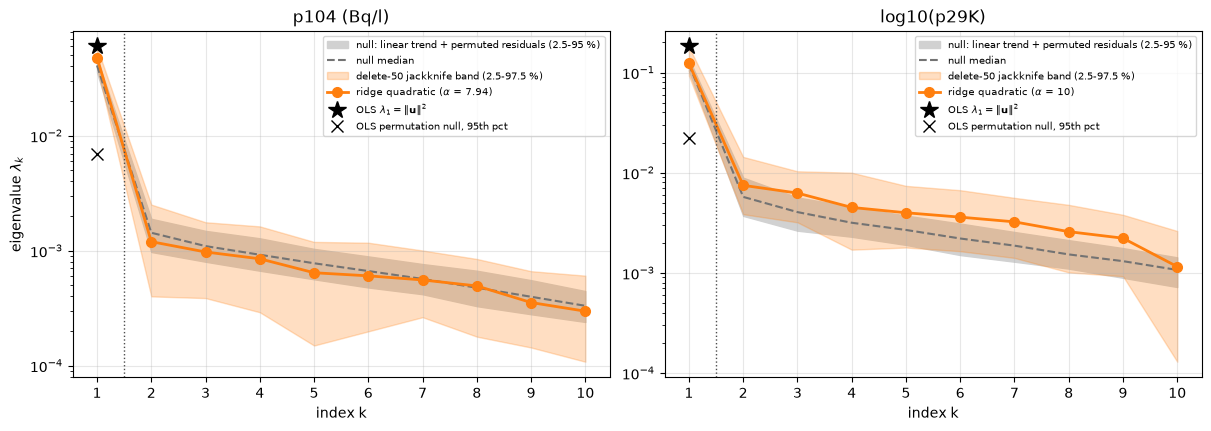

In [9]:
k = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for ax, w in zip(axes, HEAD):
    r = res[w]
    ax.fill_between(k, *np.percentile(r['null_lin'], [2.5, 95], 0)[:, :10], color='0.82',
                    label='null: linear trend + permuted residuals (2.5-95 %)')
    ax.semilogy(k, np.median(r['null_lin'], 0)[:10], '--', color='0.45', lw=1.5, label='null median')
    ax.fill_between(k, *np.clip(np.percentile(r['sub_lam_jk'], [2.5, 97.5], 0)[:, :10], 1e-6, None), color='C1', alpha=0.25,
                    label=f'delete-{M - MSUB} jackknife band (2.5-97.5 %)')
    ax.semilogy(k, r['lam'][:10], 'o-', color='C1', lw=2, ms=7, label=rf'ridge quadratic ($\alpha$ = {r["alpha"]:.3g})')
    ax.semilogy([1], r['ols'].eigenvalues[:1], 'k*', ms=13, label=r'OLS $\lambda_1 = \|\mathbf{u}\|^2$')
    ax.semilogy([1], [np.percentile(r['ols_null'], 95)], 'kx', ms=9, label='OLS permutation null, 95th pct')
    ax.axvline(1.5, color='0.3', ls=':', lw=1)
    ax.set_title(f'{TRANS[w]}({w})' if TRANS[w] == 'log10' else f'{w} (Bq/l)'); ax.set_xlabel('index k')
    ax.set_xticks(k); ax.grid(alpha=0.3); ax.legend(fontsize=7.5, loc='upper right')
axes[0].set_ylabel(r'eigenvalue $\lambda_k$')
plt.close(fig)
fig

For p104 the quadratic's $\lambda_2 = 0.0012$ lies below the one-direction null's median (0.0014) and 95th percentile (0.0019): the concentration at p104 is, within what 300 runs can resolve, a function of one linear combination of the inputs plus scatter that has no further low-dimensional structure. For $\log_{10}$ p29K, $\lambda_2 = 0.0075$ is inside that null (95th percentile 0.0089), and $\lambda_3$ and $\lambda_5$ to $\lambda_9$ lie a little above the null's 95th percentile, a weak spread of nonlinear structure over many directions rather than a second direction. The jackknife bands of $\lambda_2$ ($[0.0004, 0.00252]$ and $[0.00385, 0.0144]$) overlap the null's. The permuted-$f$ null gives practically zero eigenvalues ($\lambda_1$ 95th percentile $5.85\cdot10^{-4}$ and $1.92\cdot10^{-3}$, because the LOO rule then picks the largest penalties), so every eigenvalue in the plot reflects a fit to signal rather than to pure noise; the one-direction null is the stricter reference.

p104: OLS direction (k = 1), mean distance: raw delete-50 subsamples 0.045, jackknife-rescaled 0.101 (97.5th pct 0.139), bootstrap 0.095 (97.5th pct 0.131)
    ridge, jackknife-rescaled mean distance, k = 1..4: [0.139 0.85  0.987 0.99 ] (raw subsamples: [0.062 0.564 0.813 0.841])
p29K: OLS direction (k = 1), mean distance: raw delete-50 subsamples 0.051, jackknife-rescaled 0.115 (97.5th pct 0.162), bootstrap 0.109 (97.5th pct 0.159)
    ridge, jackknife-rescaled mean distance, k = 1..4: [0.157 0.789 0.833 0.95 ] (raw subsamples: [0.071 0.566 0.516 0.696])


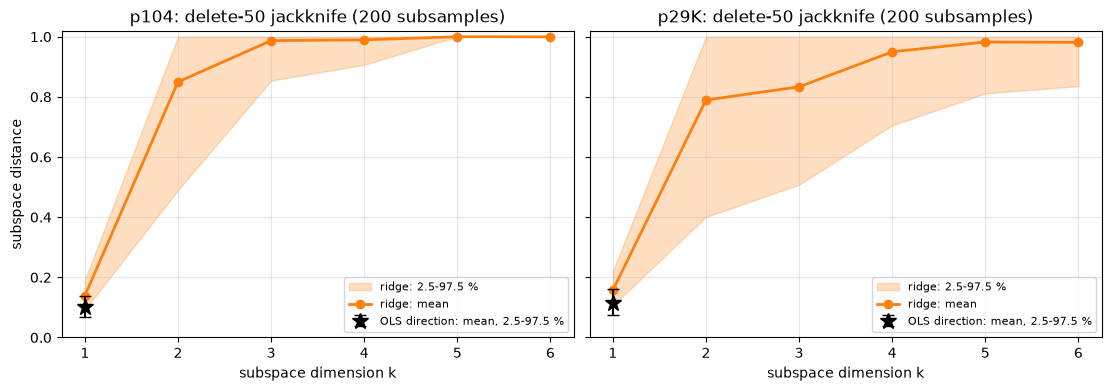

In [10]:
kk = np.arange(1, 7)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True, sharey=True)
for ax, w in zip(axes, HEAD):
    r = res[w]; bd = r['ols'].bootstrap_distances[:, 0]; dj = r['sub_dist_jk']; oj = r['sub_ols_jk']
    ax.fill_between(kk, *np.percentile(dj, [2.5, 97.5], 0), color='C1', alpha=0.25, label='ridge: 2.5-97.5 %')
    ax.plot(kk, dj.mean(0), 'o-', color='C1', lw=2, label='ridge: mean')
    ax.errorbar([1], [oj.mean()], yerr=[[oj.mean() - np.percentile(oj, 2.5)], [np.percentile(oj, 97.5) - oj.mean()]],
                fmt='k*', ms=12, capsize=4, label='OLS direction: mean, 2.5-97.5 %')
    ax.set_title(f'{w}: delete-{M - MSUB} jackknife ({NSUB} subsamples)'); ax.set_xlabel('subspace dimension k')
    ax.set_xticks(kk); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
    print(f'{w}: OLS direction (k = 1), mean distance: raw delete-{M - MSUB} subsamples {r["sub_ols"].mean():.3f}, '
          f'jackknife-rescaled {oj.mean():.3f} (97.5th pct {np.percentile(oj, 97.5):.3f}), bootstrap {bd.mean():.3f} '
          f'(97.5th pct {np.percentile(bd, 97.5):.3f})')
    print(f'    ridge, jackknife-rescaled mean distance, k = 1..4: ' + np.array2string(dj.mean(0)[:4], precision=3)
          + f' (raw subsamples: ' + np.array2string(r['sub_dist'].mean(0)[:4], precision=3) + ')')
axes[0].set_ylabel('subspace distance')
plt.close(fig)
fig

On the same delete-50 jackknife footing, the OLS direction has mean subspace distance 0.101 (p104) and 0.115 (p29K), close to its bootstrap means 0.095 and 0.109; the raw subsample means (0.045 and 0.051) are less than half of these, which is why the bands are rescaled. The ridge quadratic's first direction is less stable than the OLS direction (mean distance 0.139 and 0.157), and its two-dimensional subspace does not settle at all (0.85 and 0.789): $n = 1$ for both wells.

p104: a = kd1 +0.903, i3 -0.365, per1 +0.162, perz2 -0.099, perz1 -0.069, d1 +0.057
    ridge w1 = kd1 +0.891, i3 -0.391, per1 +0.163, perz2 -0.095;  squared weight of the top 3 inputs in a: 0.975
    |cos| with the normalized SRRC vector of Table 2: a 0.986, with the notebook SRRC 0.991
    notebook SRRC (x 100): kd1 +89, i3 -30, per1 +16, per3 -9, perz2 -8;  largest |a| over d1-d3, dt1-dt3, poros, i1, i2: 0.057;  shares of |a|^2: kd1 0.815, i3 0.133, per1 0.026
p29K: a = kd2 -0.788, kd1 -0.346, i3 +0.339, per2 +0.229, perz1 +0.213, per1 -0.156
    ridge w1 = kd2 -0.788, i3 +0.353, kd1 -0.327, per2 +0.236;  squared weight of the top 3 inputs in a: 0.855
    |cos| with the normalized SRRC vector of Table 2: a 0.997, with the notebook SRRC 0.998
    notebook SRRC (x 100): kd2 -74, i3 +32, kd1 -31, per2 +22, perz1 +21;  largest |a| over d1-d3, dt1-dt3, poros, i1, i2: 0.031;  shares of |a|^2: kd2 0.620, kd1 0.119, i3 0.115
Table 2 entries equal to the notebook SRRC x 100 (rounded): 54 of 

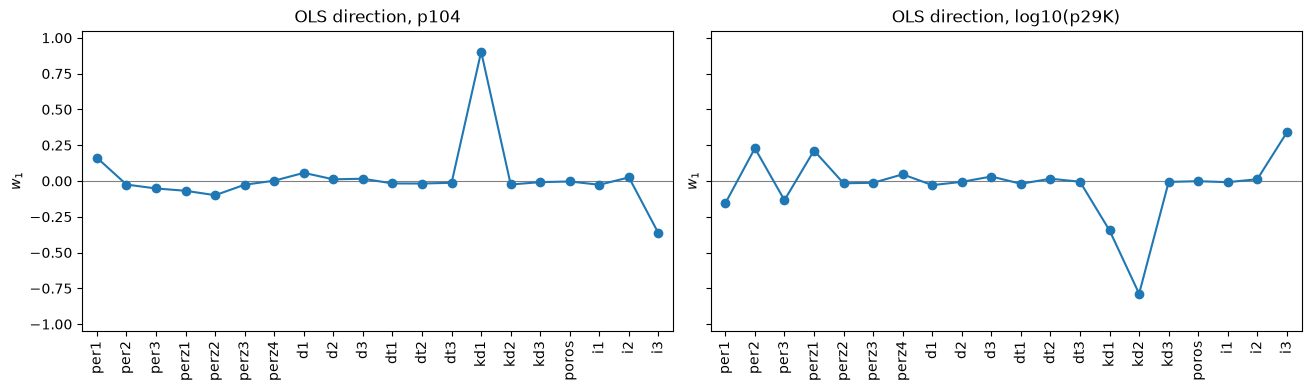

In [11]:
# Table 2 of the paper (p. 28): SRRC x 100 of the rank regression, entries with |SRRC| >= 0.10 only
SRRC_PAPER = {
    'p102K': {'kd1': 33, 'kd2': 83, 'i2': -12, 'i3': -34, 'per2': -17},
    'p104':  {'kd1': 89, 'i3': -30, 'per1': 16},
    'p106':  {'kd1': -63, 'per1': -15, 'per2': 10, 'perz1': 57},
    'p2.76': {'kd1': 32, 'kd2': -30, 'per2': 16},
    'p29K':  {'kd1': -31, 'kd2': -74, 'i3': 32, 'per1': -14, 'per2': 22, 'per3': -14, 'perz1': 21},
    'p31K':  {'kd1': 15, 'kd2': 69, 'i3': -46, 'per1': 15, 'per2': -13, 'per3': 13},
    'p35K':  {'kd1': -12, 'kd2': -56, 'i3': 49, 'per1': -25, 'per2': 12, 'per3': -17, 'perz1': 16},
    'p37K':  {'kd1': 15, 'kd2': -19, 'kd3': 16, 'i3': -66, 'per1': 38, 'per2': 15},
    'p38':   {'kd1': 48, 'kd2': 39, 'i3': -21, 'per1': 14, 'per2': -14, 'per3': -14, 'perz4': 13},
    'p4b':   {'kd2': 44, 'i2': 13, 'i3': 44, 'per2': -19, 'per3': -22, 'perz2': 17},
}
def srrc_vec(w):
    v = np.zeros(m)
    for n, s in SRRC_PAPER[w].items(): v[names.index(n)] = s
    return v / np.linalg.norm(v)
top = lambda v, k=5: ', '.join(f'{names[i]} {v[i]:+.3f}' for i in np.argsort(-np.abs(v))[:k])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True, sharey=True)
for ax, w in zip(axes, HEAD):
    r = res[w]
    ac.plotting.plot_eigenvectors(r['ols'], indices=[0], labels=names, ax=[ax])
    ax.set_title(f'OLS direction, {TRANS[w]}({w})' if TRANS[w] == 'log10' else f'OLS direction, {w}')
    ax.tick_params(axis='x', labelrotation=90)
    print(f'{w}: a = ' + top(r['a'], 6))
    print(f'    ridge w1 = ' + top(r['W'][:, 0], 4) + f';  squared weight of the top 3 inputs in a: '
          f'{np.sort(r["a"] ** 2)[::-1][:3].sum():.3f}')
    print(f'    |cos| with the normalized SRRC vector of Table 2: a {abs(r["a"] @ srrc_vec(w)):.3f}, '
          f'with the notebook SRRC {abs(r["a"] @ srrc[w]) / np.linalg.norm(srrc[w]):.3f}')
    print(f'    notebook SRRC (x 100): ' + ', '.join(f'{names[i]} {100 * srrc[w][i]:+.0f}' for i in np.argsort(-np.abs(srrc[w]))[:5])
          + f';  largest |a| over d1-d3, dt1-dt3, poros, i1, i2: {np.abs(r["a"][[7, 8, 9, 10, 11, 12, 16, 17, 18]]).max():.3f}'
          + ';  shares of |a|^2: ' + ', '.join(f'{names[i]} {r["a"][i] ** 2:.3f}' for i in np.argsort(-np.abs(r["a"]))[:3]))
# every Table 2 entry against the notebook's SRRC (x 100, rounded), and notebook entries >= 0.10 missing from Table 2
ent = [(w, n, s, round(100 * srrc[w][names.index(n)])) for w in WELLS for n, s in SRRC_PAPER[w].items()]
print(f'Table 2 entries equal to the notebook SRRC x 100 (rounded): {sum(s == t for _, _, s, t in ent)} of {len(ent)}')
miss = [(w, names[i], srrc[w][i]) for w in WELLS for i in range(m) if abs(srrc[w][i]) >= 0.10 and names[i] not in SRRC_PAPER[w]]
print('notebook |SRRC| >= 0.10 not in Table 2: ' + (', '.join(f'{w} {n} {s:+.3f}' for w, n, s in miss) or 'none'))
plt.close(fig)
fig

At p104 the active direction is dominated by kd1, the distribution coefficient of the first layer ($+0.903$, a share 0.815 of $\lVert\mathbf a\rVert^2$), with i3, the leakage-zone infiltration ($-0.365$), and per1 ($+0.162$) next; the top three carry 0.975 of the squared length. More sorption in layer 1 raises the 2010 concentration at this well and more leakage infiltration lowers it. At p29K ($\log_{10}$) the direction is led by kd2 ($-0.788$), then kd1 ($-0.346$) and i3 ($+0.339$), with smaller weights on per2 ($+0.229$) and perz1 ($+0.213$): more sorption in either upper layer lowers the concentration there, and more infiltration raises it. The dispersivities, the porosity and the infiltration rates i1 and i2 have weights of at most 0.057 (p104) and 0.031 (p29K), in line with the paper's finding that dispersivities and porosity hardly matter (Sec. 4.5). The OLS directions are at $|\cos| = 0.986$ (p104) and 0.997 (p29K) from the paper's SRRC vectors in Table 2 (entries $\ge 0.10$ only), and the notebook's own SRRC reproduce Table 2: all 54 entries of the 10 wells agree to the integer (p104: kd1 $+89$, i3 $-30$, per1 $+16$; p29K: kd2 $-74$, i3 $+32$, kd1 $-31$, per2 $+22$, perz1 $+21$). Table 2 has no dispersivity columns, although the rank regression gives an SRRC of $+0.134$ for dt3 at p38, the only entry $\ge 0.10$ missing from it. On the concentration scale this effect is small: the OLS component of dt3 at p38 is $-0.042$, with bootstrap 95 % interval $[-0.174, +0.117]$ (printed with the compact table below).

p104: y1 in [-1.31, 1.28]; corr(f, y1) 0.9351, rank corr 0.9552
    lowest 10 % of y1: median f 0.00333; highest 10 %: 0.418; runs with concentration < 1e-3 Bq/l: 10, at y1 <= -0.84
p29K: y1 in [-1.42, 1.50]; corr(f, y1) 0.9177, rank corr 0.9306
    lowest 10 % of y1: median f -0.259; highest 10 %: 0.498; runs with concentration < 1e-3 Bq/l: 0


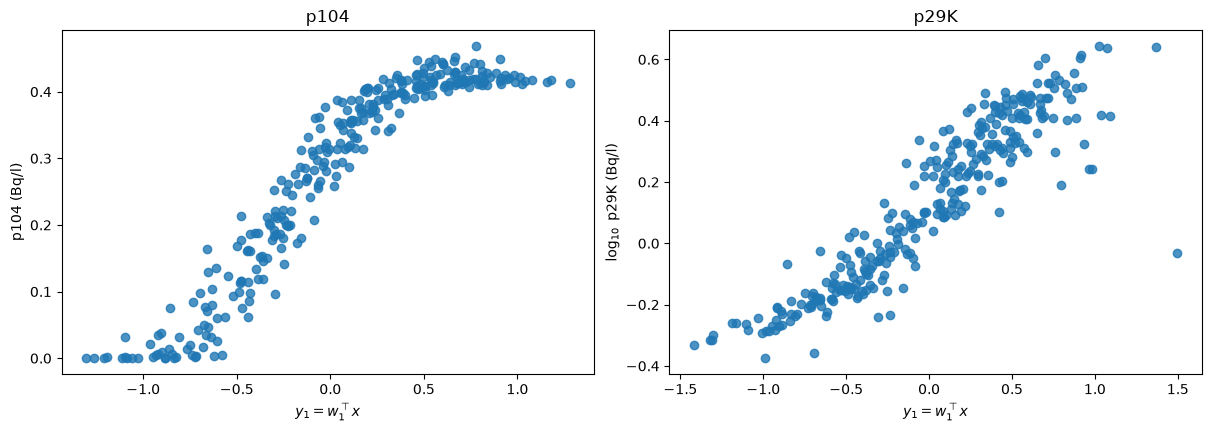

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
srank = lambda v: np.argsort(np.argsort(v))
for ax, w in zip(axes, HEAD):
    r = res[w]; f = r['f']; y1 = Z @ r['a']
    lab = rf'$\log_{{10}}$ {w} (Bq/l)' if TRANS[w] == 'log10' else f'{w} (Bq/l)'
    ac.plotting.plot_sufficient_summary(r['ols'], X=U, f=f, dims=1, qoi_label=lab, ax=ax)
    ax.set_title(w)
    print(f'{w}: y1 in [{y1.min():.2f}, {y1.max():.2f}]; corr(f, y1) {np.corrcoef(f, y1)[0, 1]:.4f}, '
          f'rank corr {np.corrcoef(srank(f), srank(y1))[0, 1]:.4f}')
    lo_ = y1 < np.percentile(y1, 10)
    print(f'    lowest 10 % of y1: median f {np.median(f[lo_]):.3g}; highest 10 %: {np.median(f[y1 > np.percentile(y1, 90)]):.3g}; '
          f'runs with concentration < 1e-3 Bq/l: {np.sum(Y[:, WELLS.index(w)] < 1e-3)}'
          + (f', at y1 <= {y1[Y[:, WELLS.index(w)] < 1e-3].max():.2f}' if np.any(Y[:, WELLS.index(w)] < 1e-3) else ''))
plt.close(fig)
fig

Both summaries show one clean, monotone trend. p104 is a sigmoid of $y_1$ (range $-1.31$ to $1.28$): near zero at the low end, where all 10 runs with almost no Sr-90 lie ($y_1 \le -0.84$; median 0.00333 Bq/l over the lowest 10 % of $y_1$), rising steeply, and levelling off at the high end (median 0.418 Bq/l over the highest 10 %); correlation with $y_1$ 0.9351, rank correlation 0.9552. $\log_{10}$ p29K increases almost linearly with $y_1$ (range $-1.42$ to $1.50$), with a wider band; correlation 0.9177, rank correlation 0.9306.

#### Surrogates on the active variable

Polynomials of degree 1 to 4 in $y_1 = \mathbf a^T\mathbf x$, with leave-one-out $R^2$ computed two ways: with $\mathbf a$ fixed at its estimate from all 300 runs (the library's fit), and nested, with $\mathbf a$ re-estimated by OLS on the training runs of every fold, the honest value. Nested 10-fold cross-validation, the paper's protocol, is given for the cubic. The plot shows the library's cubic.

p104: LOO R^2 of a polynomial in y1, degree 1..4, a fixed (library): 0.872, 0.911, 0.949, 0.958  (same with numpy: 0.949 for the cubic)
    a re-estimated in every fold (nested), LOO, degree 1..4: 0.854, 0.899, 0.937, 0.949;  nested 10-fold, cubic: 0.933  (linear model in all 20 inputs 0.854, ridge quadratic 0.827)


p29K: LOO R^2 of a polynomial in y1, degree 1..4, a fixed (library): 0.839, 0.832, 0.880, 0.878  (same with numpy: 0.880 for the cubic)
    a re-estimated in every fold (nested), LOO, degree 1..4: 0.815, 0.809, 0.868, 0.866;  nested 10-fold, cubic: 0.862  (linear model in all 20 inputs 0.815, ridge quadratic 0.777)


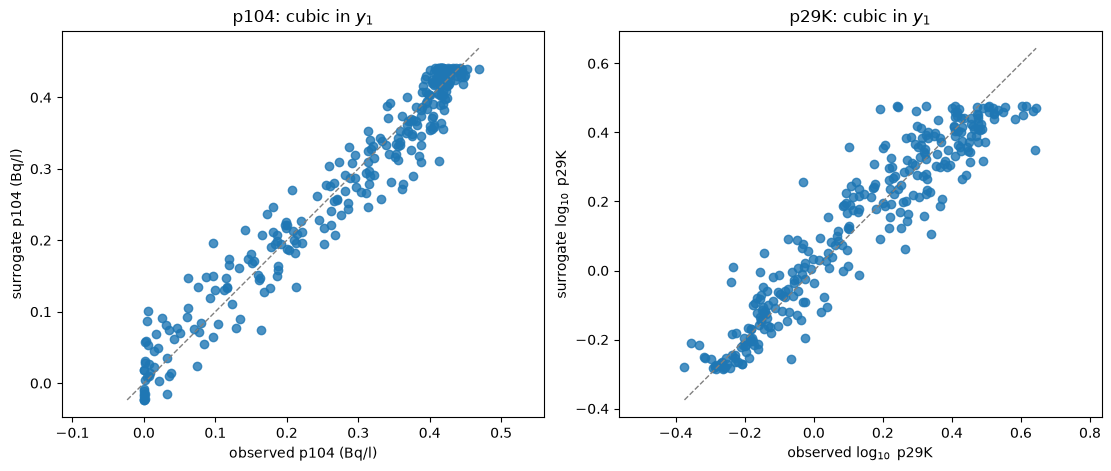

In [13]:
def cubic_cv(Zs, f, folds, deg=3, a_fix=None, target=None):
    """Cross-validated R^2 of a degree-deg polynomial in y1 = a^T z. With a_fix=None the direction a is
    re-estimated (OLS) on the training rows of every fold (nested); otherwise a_fix is used in every fold.
    target: the output fitted by the polynomial (default f, the output that defines a)."""
    t = f if target is None else target; pred = np.empty(len(f))
    for te in folds:
        tr = np.setdiff1d(np.arange(len(f)), te)
        a_ = a_fix if a_fix is not None else loo_lin(Zs[tr], f[tr])[0]
        p = np.polyfit(Zs[tr] @ a_, t[tr], deg); pred[te] = np.polyval(p, Zs[te] @ a_)
    return 1 - np.sum((t - pred) ** 2) / np.sum((t - t.mean()) ** 2)
LOO_FOLDS = [np.array([i]) for i in range(M)]
TEN_FOLDS = np.array_split(np.random.default_rng(SEED).permutation(M), 10)    # the paper's protocol: 10-fold CV

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for ax, w in zip(axes, HEAD):
    r = res[w]; f = r['f']
    surs = {d: ac.fit_surrogate(X=U, f=f, space=space, subspace=r['ols'], kind='poly', degree=d) for d in (1, 2, 3, 4)}
    r['loo_sur'] = {d: s.loo_r_squared for d, s in surs.items()}
    r['loo_nest'] = {d: cubic_cv(Z, f, LOO_FOLDS, d) for d in (1, 2, 3, 4)}
    r['cv10_nest'] = cubic_cv(Z, f, TEN_FOLDS, 3)
    print(f'{w}: LOO R^2 of a polynomial in y1, degree 1..4, a fixed (library): '
          + ', '.join(f'{s.loo_r_squared:.3f}' for s in surs.values())
          + f'  (same with numpy: {cubic_cv(Z, f, LOO_FOLDS, 3, a_fix=r["a"]):.3f} for the cubic)')
    print(f'    a re-estimated in every fold (nested), LOO, degree 1..4: '
          + ', '.join(f'{v:.3f}' for v in r['loo_nest'].values()) + f';  nested 10-fold, cubic: {r["cv10_nest"]:.3f}'
          + f'  (linear model in all 20 inputs {r["loo_lin"]:.3f}, ridge quadratic {r["loo_ridge"]:.3f})')
    ac.plotting.plot_surrogate_fit(surs[3], X=U, f=f, ax=ax,
                                   qoi_label=rf'$\log_{{10}}$ {w}' if TRANS[w] == 'log10' else f'{w} (Bq/l)')
    ax.set_title(f'{w}: cubic in $y_1$')
plt.close(fig)
fig

With the direction re-estimated in every fold, a cubic in the one active variable has LOO $R^2 = 0.937$ at p104 and 0.868 at p29K ($\log_{10}$), above both the 20-input linear model (0.854, 0.815) and the 20-input ridge quadratic (0.827, 0.777); at these two wells, keeping $\mathbf a$ fixed at its full-data estimate overstates the value only slightly (0.949, 0.880). Nested 10-fold cross-validation, the protocol of the paper's boosting-tree response surface on all 20 inputs, gives 0.933 at p104, against the paper's 0.94 (Table 3). At p29K the paper's 0.82 is for the concentration itself, so it and our 0.862 are on different scales. A degree-4 polynomial adds little (nested LOO 0.949 and 0.866).

### All ten wells

The same analysis in compact form (OLS bootstrap with 200 resamples and nulls with 100 permutations each, all from the one seed). The columns are: the scale used; the linear model's LOO $R^2$; $\lambda_1^{OLS}$ over the 95th percentile of its permutation null; the OLS bootstrap mean distance; the ridge quadratic's LOO $R^2$; $\lambda_2$ over the 95th percentile of the one-direction null (above 1: structure beyond one direction); $|\mathbf a^T\mathbf w_1|$; the LOO $R^2$ of a cubic in $y_1$, with $\mathbf a$ fixed and nested ($\mathbf a$ re-estimated in every fold); $|\cos|$ with the paper's SRRC vector; the three largest components of $\mathbf a$; and the paper's boosting $R^2$ and largest total Sobol' index (Table 3). A second table repeats the fits on the rank scale, with the output replaced by its ranks over the 300 runs (the output scale of the paper's $R^{2*}$) and the same input coordinates.

In [14]:
# Table 3 of the paper (p. 28): boosting-tree 10-fold cross-validation R^2 and the largest total Sobol index
TABLE3 = {'p102K': (0.75, 'kd2', 69), 'p104': (0.94, 'kd1', 93), 'p106': (0.28, 'kd1', 82), 'p2.76': (0.57, 'kd2', 68),
          'p29K': (0.82, 'kd2', 66), 'p31K': (0.45, 'kd2', 94), 'p35K': (0.56, 'kd2', 91), 'p37K': (0.64, 'i3', 52),
          'p38': (0.31, 'kd1', 60), 'p4b': (0.39, 'kd2', 71)}
NB_ALL, NN_ALL = 200, 100
rng = np.random.default_rng(SEED)
rows_out, summary = [], {}
for w in WELLS:
    f = qoi(w)
    u, loo1 = loo_lin(Z, f); a = u / np.linalg.norm(u); a *= np.sign(np.cov(Z @ a, f)[0, 1])
    perm95 = np.percentile([np.sum(loo_lin(Z, rng.permutation(f))[0] ** 2) for _ in range(NN_ALL)], 95)
    bd, bv = [], []
    for _ in range(NB_ALL):
        rows = rng.integers(0, M, M); ub = loo_lin(Z[rows], f[rows])[0]; bd.append(np.sqrt(max(0, 1 - (ub @ a) ** 2 / (ub @ ub))))
        bv.append(ub / np.linalg.norm(ub) * np.sign(ub @ a))
    alpha, c, loo2 = rq.fit(f); lam, W = np.linalg.eigh(grad_matrix(c)); lam, W = lam[::-1], W[:, ::-1]
    trend = np.column_stack([np.ones(M), Z]) @ np.linalg.lstsq(np.column_stack([np.ones(M), Z]), f, rcond=None)[0]
    nl = np.array([eigdesc(grad_matrix(rq.fit(trend + rng.permutation(f - trend))[1]))[:2] for _ in range(NN_ALL)])
    loo3 = ac.fit_surrogate(X=U, f=f, space=space, subspace=ac.subspace_from_matrix(
        np.outer(a, a), space=space, n=1), kind='poly', degree=3).loo_r_squared
    # rank scale: ranks of f (over all 300 runs, as in the paper's R^2*), same coordinates
    fr = rank(f) / (M - 1)
    ur, loo_rk = loo_lin(Z, fr)
    summary[w] = dict(a=a, loo1=loo1, sig=np.sum(u ** 2) / perm95, dist=np.mean(bd), loo2=loo2, l12=lam[0] / lam[1],
                      l2null=lam[1] / np.percentile(nl[:, 1], 95), aw=abs(a @ W[:, 0]), loo3=loo3,
                      loo3n=cubic_cv(Z, f, LOO_FOLDS, 3), cos_srrc=abs(a @ srrc_vec(w)), boot_a=np.array(bv),
                      loo_rk=loo_rk, cos_rk=abs(ur @ a) / np.linalg.norm(ur), loo_rk_cub=cubic_cv(Z, f, LOO_FOLDS, 3, target=fr))
print(f"{'well':6s} {'f':5s} {'LOO lin':>7s} {'l1/null95':>9s} {'boot d1':>7s} {'LOO rq':>6s} "
      f"{'l2/null95':>9s} {'|a.w1|':>6s} {'cub fix':>7s} {'cub nest':>8s} {'|cos SRRC|':>10s}  top 3 of a{'':22s} paper: R2, top S_T")
for w in WELLS:
    s = summary[w]
    print(f"{w:6s} {TRANS[w]:5s} {s['loo1']:7.3f} {s['sig']:9.1f} {s['dist']:7.3f} {s['loo2']:6.3f} "
          f"{s['l2null']:9.2f} {s['aw']:6.3f} {s['loo3']:7.3f} {s['loo3n']:8.3f} {s['cos_srrc']:10.3f}  {top(s['a'], 3):34s} "
          f"{TABLE3[w][0]:5.2f}, {TABLE3[w][1]} {TABLE3[w][2]} %")
lead = {w: names[np.argmax(np.abs(summary[w]['a']))] for w in WELLS}
print(f'nested cubic-in-y1 LOO R^2 above the paper\'s boosting R^2 at {sum(summary[w]["loo3n"] > TABLE3[w][0] for w in WELLS)} of 10 wells '
      f'(with a fixed: {sum(summary[w]["loo3"] > TABLE3[w][0] for w in WELLS)})')
print(f'largest |a| component = input with the largest total Sobol index in Table 3: '
      f'{sum(lead[w] == TABLE3[w][1] for w in WELLS)} of {len(WELLS)} wells; differs at '
      + (', '.join(f'{w} ({lead[w]} vs {TABLE3[w][1]})' for w in WELLS if lead[w] != TABLE3[w][1]) or 'none'))
j = names.index('dt3'); bq = np.percentile(summary['p38']['boot_a'][:, j], [2.5, 97.5])
print(f'p38: OLS component of dt3 {summary["p38"]["a"][j]:+.3f}, bootstrap 2.5-97.5 % [{bq[0]:+.3f}, {bq[1]:+.3f}]')
print()
print('Rank scale: the output replaced by its ranks; LOO R^2 of the linear model in all 20 inputs, |cos| of its direction')
print('with the OLS direction a of the table above, and nested LOO R^2 of a cubic in y1 = a^T x (a refitted on f in each fold)')
print(f"{'well':6s} {'f':5s} {'LOO lin f':>9s} {'LOO lin rank':>12s} {'|cos| a_rank, a':>15s} {'cub nest f':>10s} {'cub nest rank':>13s} {'R2* paper':>9s}")
for w in WELLS:
    s = summary[w]
    print(f"{w:6s} {TRANS[w]:5s} {s['loo1']:9.3f} {s['loo_rk']:12.3f} {s['cos_rk']:15.3f} {s['loo3n']:10.3f} {s['loo_rk_cub']:13.3f} {R2_STAR_PAPER[w]:9.2f}")

well   f     LOO lin l1/null95 boot d1 LOO rq l2/null95 |a.w1| cub fix cub nest |cos SRRC|  top 3 of a                       paper: R2, top S_T
p102K  f       0.490       5.6   0.221  0.414      1.09  0.994   0.649    0.550      0.969  kd2 +0.766, i3 -0.435, kd1 +0.365   0.75, kd2 69 %
p104   f       0.854       8.3   0.099  0.827      0.62  0.998   0.949    0.937      0.986  kd1 +0.903, i3 -0.365, per1 +0.162  0.94, kd1 93 %
p106   log10   0.222       3.6   0.333  0.339      2.34  0.983   0.646    0.367      0.893  kd1 -0.765, perz1 +0.497, perz3 +0.228  0.28, kd1 82 %
p2.76  f       0.125       2.0   0.426  0.309      5.02  0.293   0.246    0.134      0.798  kd1 +0.778, per2 +0.293, i3 -0.264  0.57, kd2 68 %
p29K   log10   0.815       8.2   0.109  0.777      0.85  0.998   0.880    0.868      0.997  kd2 -0.788, kd1 -0.346, i3 +0.339   0.82, kd2 66 %
p31K   f       0.343       4.9   0.268  0.369      0.84  0.992   0.743    0.623      0.971  kd2 +0.785, i3 -0.514, kd1 +0.213   0.45, kd2

At every well the OLS direction is above its permutation null (ratio 2.0 to 8.3), close to the paper's SRRC vector ($|\cos|$ 0.798 to 0.997) and, except at p2.76, close to the ridge quadratic's first direction ($|\mathbf a^T\mathbf w_1| \ge 0.934$). Its largest component is the input with the largest total Sobol' index in the paper at 9 of the 10 wells. The wells fall into the paper's groups: kd1 leads at p104, p106, p38 (and p2.76), kd2 at p102K, p29K, p31K, p35K and p4b, and i3 at p37K.

Beyond the two headline wells the linear model explains 12–49 % of the variance and the one-variable cubic, with its direction re-estimated in every fold, 13–62 % (0.134 at p2.76 to 0.623 at p31K). With $\mathbf a$ fixed the same cubic gives 0.246 to 0.743, so fixing the direction is far from slightly optimistic at these wells. These are statements about the concentration scale only. On the rank scale a linear model in the same coordinates has LOO $R^2$ 0.522 to 0.882 at six of the eight wells (p102K 0.882, p106 0.704, p31K 0.661, p37K 0.630, p35K 0.624, p4b 0.522), its direction is at $|\cos|$ 0.920 to 0.981 from the concentration-scale $\mathbf a$ at all eight, and a cubic of the ranks in the concentration-scale $y_1$ (nested) explains 0.505 to 0.848 of the rank variance at the same six. At these wells the concentration is, to a fair approximation, a monotone function of one direction, but strongly curved or skewed (skewness up to 5.62 at p106 and $-3.42$ at p38, above), which a low-degree polynomial in $y_1$ does not follow; the rank-scale values are close to the paper's in-sample $R^{2*}$ (Table 2). Only p2.76 (rank-scale LOO $R^2$ 0.198) and p38 (0.392) are poorly described by one direction on either scale.

At five wells $\lambda_2$ lies above the one-direction null's 95th percentile: marginally at p102K (factor 1.09) and p37K (1.68), clearly at p106 (2.34), p38 (3.33; kd1 and kd2 both carry large weights) and especially p2.76 (5.02). At p2.76 the linear model explains only 12.5 % (LOO) while the quadratic reaches 30.9 %, the quadratic's direction is nearly orthogonal to the OLS one ($|\mathbf a^T\mathbf w_1| = 0.293$), and the paper's largest Sobol' index is kd2 rather than our kd1: a sign of a non-monotone or interacting dependence that neither a line nor one direction captures. The nested cubic's LOO $R^2$ exceeds the paper's boosting $R^2$ at 4 of the 10 wells (5 with $\mathbf a$ fixed; for p106 and p29K on the $\log_{10}$ scale, so not like for like).

**Checks** on the headline wells: (a) the same linear model in physical coordinates, each input scaled by its own standard deviation instead of mapped through its distribution; (b) OLS on the two Latin-hypercube blocks (rows 1–200) and on the other 100 rows separately; (c) the other output scale.

In [15]:
for w in HEAD:
    r = res[w]; f = r['f']
    # (a) physical coordinates, each input scaled by its own sample standard deviation (no CDF map)
    Xs = (X - X.mean(0)) / X.std(0)
    u_p, loo_p = loo_lin(Xs, f); a_p = u_p / np.linalg.norm(u_p)
    print(f'{w}: physical inputs scaled by their own sd: linear LOO R^2 {loo_p:.3f} (CDF coordinates {r["loo_lin"]:.3f}); '
          f'leading components ' + top(a_p * np.sign(a_p @ r["a"]), 3))
    # (b) the two Latin-hypercube blocks (rows 1-200) against the other 100 rows
    a1 = loo_lin(Z[:200], f[:200])[0]; a2 = loo_lin(Z[200:], f[200:])[0]
    print(f'    OLS direction on rows 1-200 vs rows 201-300: |cos| with a {abs(a1 @ r["a"]) / np.linalg.norm(a1):.3f} and '
          f'{abs(a2 @ r["a"]) / np.linalg.norm(a2):.3f}, with each other {abs(a1 @ a2) / np.linalg.norm(a1) / np.linalg.norm(a2):.3f}')
    # (c) the other output scale
    g = Y[:, WELLS.index(w)] if TRANS[w] == 'log10' else np.log10(Y[:, WELLS.index(w)])
    u_g, loo_g = loo_lin(Z, g)
    print(f'    {"f" if TRANS[w] == "log10" else "log10 f"} instead: linear LOO R^2 {loo_g:.3f}, |cos| of its OLS direction with a '
          f'{abs(u_g @ r["a"]) / np.linalg.norm(u_g):.3f}')
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

p104: physical inputs scaled by their own sd: linear LOO R^2 0.625 (CDF coordinates 0.854); leading components kd1 +0.863, i3 -0.429, per1 +0.160
    OLS direction on rows 1-200 vs rows 201-300: |cos| with a 0.997 and 0.985, with each other 0.971
    log10 f instead: linear LOO R^2 0.333, |cos| of its OLS direction with a 0.918
p29K: physical inputs scaled by their own sd: linear LOO R^2 0.585 (CDF coordinates 0.815); leading components kd2 -0.757, i3 +0.362, kd1 -0.334
    OLS direction on rows 1-200 vs rows 201-300: |cos| with a 0.996 and 0.975, with each other 0.953
    f instead: linear LOO R^2 0.717, |cos| of its OLS direction with a 0.997
Total run time: 60 s


(a) Without the distribution map the linear model is much worse (LOO $R^2$ 0.625 and 0.585 against 0.854 and 0.815), because the heavy-tailed kd values enter linearly, but the leading components are the same (kd1 $+0.863$, i3 $-0.429$, per1 $+0.160$ for p104; kd2 $-0.757$, i3 $+0.362$, kd1 $-0.334$ for p29K). (b) The first 200 rows and the last 100 rows give directions at $|\cos|$ 0.997 and 0.985 (p104) and 0.996 and 0.975 (p29K) from $\mathbf a$, so the two parts of the file agree. (c) For p104 the logarithm fits far worse (LOO $R^2$ 0.333) and turns the direction by $|\cos| = 0.918$; for p29K the concentration itself gives LOO $R^2$ 0.717 and a direction at $|\cos| = 0.997$, so its direction does not depend on the scale.

### Comparison with the paper

The paper reports no active subspace. Its comparable results are the rank regression (Table 2) and the boosting-tree response surfaces with total Sobol' indices (Table 3).

| quantity | paper | notebook |
|---|---|---|
| runs and design | 300 Latin hypercube runs (Sec. 4.1), 20 wells, 18 analysed | 300 runs at 10 wells (VLSE file); rows 1–200 two Latin hypercubes of 100, rows 201–300 not Latin |
| input dependence | d$_k$–dt$_k$ correlations "significant", i1–i3 "do not really correlate" (Sec. 4.1); not printed | d$_k$–dt$_k$ $+0.692$ to $+0.731$ in physical units; removed by the conditional CDF map (largest remaining 0.102) |
| rank-regression $R^{2*}$, 10 wells | Table 2 | identical to two decimals at all 10 wells |
| p104: SRRC (× 100) | kd1 89, i3 −30, per1 16 | kd1 +89, i3 −30, per1 +16; OLS direction kd1 +0.903, i3 −0.365, per1 +0.162 ($\lvert\cos\rvert$ 0.986 with the SRRC vector) |
| p104: total Sobol' indices, response surface $R^2$ | kd1 93 %, i3 4 %, per1 3 %; boosting $R^2$ 0.94 | kd1 share of $\lVert\mathbf a\rVert^2$ 0.815; cubic in $y_1$, $\mathbf a$ re-estimated in every fold: LOO $R^2$ 0.937, 10-fold 0.933 |
| p29K: SRRC (× 100) | kd2 −74, i3 32, kd1 −31, per2 22, perz1 21, per1 −14, per3 −14 | same (all 54 Table 2 entries of the 10 wells agree to the integer); OLS direction ($\log_{10}$) kd2 −0.788, kd1 −0.346, i3 +0.339 ($\lvert\cos\rvert$ 0.997) |
| p29K: total Sobol' indices, $R^2$ | kd2 66 %, kd1 19 %, i3 3 %; boosting $R^2$ 0.82 (concentration) | i3 weight +0.339 (share 0.115), larger than its 3 % Sobol' index but as in the paper's own SRRC; cubic in $y_1$ (nested) LOO $R^2$ 0.868 ($\log_{10}$) |
| most influential input per well | largest total Sobol' index, Table 3 | largest component of $\mathbf a$ agrees at 9 of 10 wells (not at p2.76: kd1 against kd2) |
| interactions | first-order and total Sobol' indices "quite close" (Sec. 4.5) | at p104 and p29K one direction carries the trend and $\lambda_2$ is at the one-direction null; $\lambda_2$ clearly above that null at p106, p38 and p2.76, marginally at p102K and p37K |
| dispersivities, porosity | "practically no influence" (Sec. 5) | weights at most 0.057 (p104) and 0.031 (p29K), together with i1 and i2; Table 2 omits dt3 at p38 (SRRC $+0.134$ here), whose OLS component is $-0.042$ (bootstrap 95 % $[-0.174, +0.117]$) |
| eigenvalues, active directions | not reported | $n = 1$. OLS $\lambda_1$ 8.6 (p104) and 8.2 ($\log_{10}$ p29K) times its permutation null's 95th percentile; ridge $\lambda_1/\lambda_2$ limited by the noise, inside the one-direction null (2.5–97.5 % $[20.7, 40.1]$ and $[13.6, 30.4]$) |
| response-surface fit, 10 wells | boosting 10-fold $R^2$ 0.28–0.94 (Table 3) | nested cubic in $y_1$: LOO $R^2$ 0.134–0.937, above the boosting $R^2$ at 4 of 10 wells; on ranks, linear LOO $R^2$ 0.198–0.889, close to $R^{2*}$ |

### References

[1] E. Volkova, B. Iooss, F. Van Dorpe. Global sensitivity analysis for a numerical model of radionuclide migration from the RRC "Kurchatov Institute" radwaste disposal site. *Stochastic Environmental Research and Risk Assessment* 22(1):17–31, 2008. [doi:10.1007/s00477-006-0093-y](https://doi.org/10.1007/s00477-006-0093-y).

[2] A. Marrel, B. Iooss, F. Van Dorpe, E. Volkova. An efficient methodology for modeling complex computer codes with Gaussian processes. *Computational Statistics & Data Analysis* 52(10):4731–4744, 2008. [doi:10.1016/j.csda.2008.03.026](https://doi.org/10.1016/j.csda.2008.03.026). (A Gaussian-process study of the same MARTHE runs, cited on the VLSE page.)

[3] S. Surjanovic, D. Bingham. Virtual Library of Simulation Experiments: Test Functions and Datasets, "MARTHE Dataset", https://www.sfu.ca/~ssurjano/marthe.html (data file https://www.sfu.ca/~ssurjano/Code/marthedata.txt, downloaded 2026-11-01). Source given there: Benchmark Proposals of GdR MASCOT-NUM, http://www.gdr-mascotnum.fr/benchmarks.html, retrieved April 2014.

[4] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[5] M. D. McKay, R. J. Beckman, W. J. Conover. A comparison of three methods for selecting values of input variables in the analysis of output from a computer code. *Technometrics* 21(2):239–245, 1979. [doi:10.1080/00401706.1979.10489755](https://doi.org/10.1080/00401706.1979.10489755).

[6] M. Rosenblatt. Remarks on a multivariate transformation. *The Annals of Mathematical Statistics* 23(3):470–472, 1952. [doi:10.1214/aoms/1177729394](https://doi.org/10.1214/aoms/1177729394).

[7] K.-C. Li, N. Duan. Regression analysis under link violation. *The Annals of Statistics* 17(3):1009–1052, 1989. [doi:10.1214/aos/1176347254](https://doi.org/10.1214/aos/1176347254).

[8] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).

### Acknowledgments

From [[1]](https://doi.org/10.1007/s00477-006-0093-y) (p. 30): the work was supported by the MRIMP project of the "Risk Control Domain", which depends on CEA/Nuclear Energy Division/Nuclear Development and Innovation Division, and is part of the Russian Research Center "Kurchatov Institute" Scientific and Technical Complex "Rehabilitation" project. The data are hosted by the Virtual Library of Simulation Experiments [[3]](https://www.sfu.ca/~ssurjano/marthe.html).